# Supplementary Material - Figure 1 - Figure Code

Loading data for 21 MTLE patients...
Fitting Full Mixed Model (MTLE)...
Model Fit Complete.
Calculating Partial R2 values...


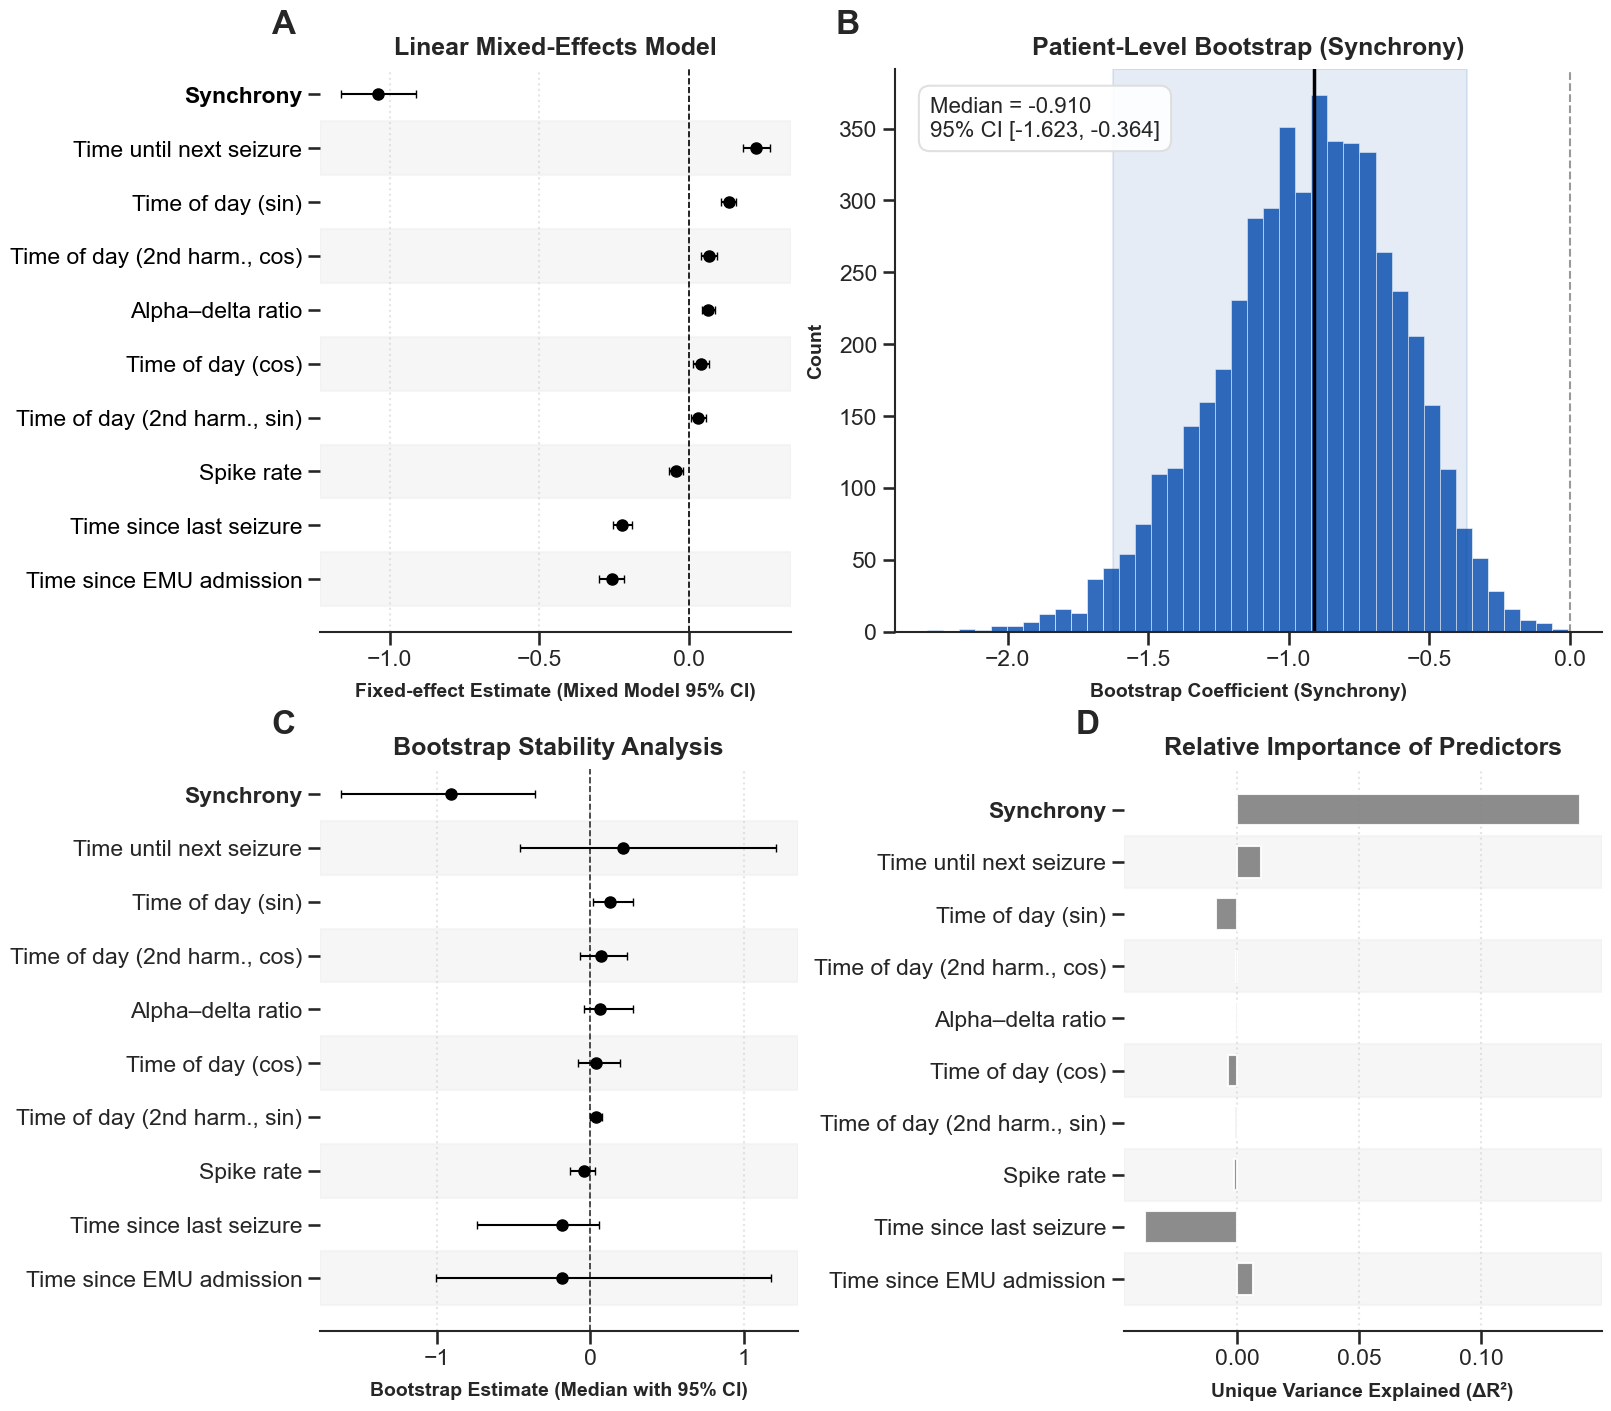

In [1]:
import os
import numpy as np
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler

# --- 1. CONFIGURATION & DATA LOADING ---

DATA_PATH = "../../cnt-data/"
TABLES_PATH = os.path.join(DATA_PATH, "revised_tables_step_4")

sns.set_style("whitegrid")
sns.set_theme(style="ticks", context="talk")

def get_patient_hup_ids(directory):
    if not os.path.exists(directory):
        print(f"Warning: Path {directory} not found.")
        return []
    files = os.listdir(directory)
    patient_hup_ids = [
        int(f.split("_")[1].split(".")[0]) for f in files if f.startswith("HUP_")
    ]
    return patient_hup_ids

# 1.1 Load SOZ Data and Filter for Mesial Temporal
soz_df = pd.read_csv(os.path.join(DATA_PATH, "HUP_SOZ.csv"))
mtle_df = soz_df[soz_df["SOZ"] == "mesial temporal"].copy()

# Extract IDs
mtle_df['pt_id'] = mtle_df['pt_id'].str.replace('HUP', '').astype(int)
mtle_patient_ids = mtle_df['pt_id'].unique().tolist()

# Get available files
completed_hup_ids = get_patient_hup_ids(TABLES_PATH)
mtle_completed_hup_ids = [pt_id for pt_id in completed_hup_ids if pt_id in mtle_patient_ids]
mtle_completed_hup_ids.sort()

print(f"Loading data for {len(mtle_completed_hup_ids)} MTLE patients...")

dfs = []
columns_to_keep = [
    "emu_minute", "synchrony_broadband", "med_sum_no_lorazepam_raw",
    "time_since_last_seizure", "time_until_next_seizure", "ad_ratio",
    "tod_sin", "tod_cos", "tod_sin2", "tod_cos2", "spike_rate", "patient_hup_id",
]

for patient_hup_id in mtle_completed_hup_ids:
    file_path = os.path.join(TABLES_PATH, f"HUP_{patient_hup_id}.csv")
    patient_features_df = pd.read_csv(file_path, low_memory=False)
    
    patient_features_df["patient_hup_id"] = patient_hup_id
    existing_columns = [c for c in columns_to_keep if c in patient_features_df.columns]
    patient_features_df = patient_features_df[existing_columns]
    dfs.append(patient_features_df)

if dfs:
    all_data = pd.concat(dfs).reset_index(drop=True)
else:
    raise ValueError("No MTLE data loaded.")

# Drop NaNs
all_data = all_data.dropna(subset=columns_to_keep).reset_index(drop=True)

# Scale Variables
scaler = StandardScaler()
cols_to_scale = [
    "synchrony_broadband", "time_since_last_seizure", "time_until_next_seizure",
    "emu_minute", "ad_ratio", "spike_rate",
]
all_data[cols_to_scale] = scaler.fit_transform(all_data[cols_to_scale])

# --- 2. DEFINE NAKAGAWA R2 FUNCTION ---

def get_nakagawa_r2(model_result):
    pred_fixed = np.dot(model_result.model.exog, model_result.fe_params)
    var_fixed = np.var(pred_fixed)
    var_random = model_result.cov_re.iloc[0, 0]
    var_resid = model_result.scale
    total_var = var_fixed + var_random + var_resid
    return {
        "marginal": var_fixed / total_var, 
        "conditional": (var_fixed + var_random) / total_var
    }

# --- 3. FIT FULL MODEL (Panel A Data) ---

outcome_var = "med_sum_no_lorazepam_raw"
predictor_vars = [
    "synchrony_broadband", "time_since_last_seizure", "time_until_next_seizure",
    "emu_minute", "ad_ratio", "tod_sin", "tod_cos", "tod_sin2", "tod_cos2", "spike_rate",
]

full_formula = outcome_var + " ~ " + " + ".join(predictor_vars)
print("Fitting Full Mixed Model (MTLE)...")

base_model = smf.mixedlm(full_formula, all_data, groups=all_data["patient_hup_id"])
base_result = base_model.fit(reml=True)
print("Model Fit Complete.")

# --- 4. CALCULATE DELTA R2 (Panel D Data) ---

full_r2_stats = get_nakagawa_r2(base_result)
partial_r2_rows = []

print("Calculating Partial R2 values...")
for var in predictor_vars:
    reduced_predictors = [v for v in predictor_vars if v != var]
    reduced_formula = outcome_var + " ~ " + " + ".join(reduced_predictors)
    
    try:
        reduced_model = smf.mixedlm(reduced_formula, all_data, groups=all_data["patient_hup_id"])
        reduced_result = reduced_model.fit(reml=True, disp=0) 
        reduced_r2_stats = get_nakagawa_r2(reduced_result)
        
        delta_r2 = full_r2_stats['marginal'] - reduced_r2_stats['marginal']
        partial_r2_rows.append({"term": var, "delta_r2": delta_r2})
    except Exception as e:
        print(f"Error on {var}: {e}")
        partial_r2_rows.append({"term": var, "delta_r2": 0})

partial_r2_df = pd.DataFrame(partial_r2_rows)

# --- 5. LOAD BOOTSTRAP DATA (Panel B & C Data) ---

input_filename = "bootstrap_results_mtle.pkl"
if not os.path.exists(input_filename):
    print(f"Warning: '{input_filename}' not found. Using Mock Data for display.")
    # Create Mock Data so the plot script works
    boot_coefs = {"synchrony_broadband": np.random.normal(-0.3, 0.1, 1000)}
    bootstrap_summary = pd.DataFrame({
        "term": predictor_vars,
        "median": np.random.uniform(-0.5, 0.5, len(predictor_vars)),
        "ci95_lower": np.random.uniform(-0.6, 0.4, len(predictor_vars)),
        "ci95_upper": np.random.uniform(-0.4, 0.6, len(predictor_vars))
    })
else:
    with open(input_filename, "rb") as f:
        saved_data = pickle.load(f)
    boot_coefs = saved_data["boot_coefs"]
    bootstrap_summary = saved_data["bootstrap_summary"]

# --- 6. PLOTTING SETUP ---

label_map = {
    "synchrony_broadband":       "Synchrony",
    "time_since_last_seizure": "Time since last seizure",
    "time_until_next_seizure": "Time until next seizure",
    "emu_minute":               "Time since EMU admission",
    "ad_ratio":                 "Alpha–delta ratio",
    "tod_sin":                  "Time of day (sin)",
    "tod_cos":                  "Time of day (cos)",
    "tod_sin2":                 "Time of day (2nd harm., sin)",
    "tod_cos2":                 "Time of day (2nd harm., cos)",
    "spike_rate":               "Spike rate"
}

# 1. Setup Figure (Constrained Layout helps with labels)
fig = plt.figure(figsize=(16, 14), constrained_layout=True)

# 2. Create Outer Grid (2 Rows)
gs_outer = fig.add_gridspec(2, 1, height_ratios=[1, 1])

# 3. Create Inner Grids (Decoupled Columns)
# TOP ROW: A vs B. B is 1.5x wider than A.
gs_top = gs_outer[0].subgridspec(1, 2, width_ratios=[1, 1.5])

# BOTTOM ROW: C vs D. Equal width.
gs_bot = gs_outer[1].subgridspec(1, 2, width_ratios=[1, 1])

# 4. Map Axes
ax_a = fig.add_subplot(gs_top[0])
ax_b = fig.add_subplot(gs_top[1])
ax_c = fig.add_subplot(gs_bot[0])
ax_d = fig.add_subplot(gs_bot[1])

ax_dict = {'A': ax_a, 'B': ax_b, 'C': ax_c, 'D': ax_d}

# ==========================================
# PANEL A: Mixed Model Fixed Effects
# ==========================================
fe_params = base_result.fe_params           
conf_int = base_result.conf_int(alpha=0.05) 
conf_int.columns = ["ci_lower", "ci_upper"]

coefs = (
    pd.concat([fe_params, conf_int], axis=1)
    .reset_index()
    .rename(columns={"index": "term", 0: "estimate"})
)
coefs = coefs[~coefs["term"].str.startswith("Group")].copy()
coefs = coefs[coefs["term"] != "Intercept"].copy()
coefs["label"] = coefs["term"].map(label_map).fillna(coefs["term"])
coefs["is_synchrony"] = coefs["term"] == "synchrony_broadband"

# Sorting Strategy: Synchrony first, then by Estimate
coefs = coefs.sort_values(by=["is_synchrony", "estimate"], ascending=[True, True]).reset_index(drop=True)

for i in range(len(coefs)):
    if i % 2 == 0:
        ax_a.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

x_err_lower = coefs["estimate"] - coefs["ci_lower"]
x_err_upper = coefs["ci_upper"] - coefs["estimate"]

ax_a.errorbar(
    x=coefs["estimate"], y=range(len(coefs)), xerr=[x_err_lower, x_err_upper],
    fmt='o', color='black', ecolor='black', capsize=3, markersize=8, linewidth=1.5, zorder=10
)

ax_a.set_yticks(range(len(coefs)))
ax_a.set_yticklabels(coefs["label"], color='black')
for i, row in coefs.iterrows():
    if row["term"] == "synchrony_broadband":
        ax_a.get_yticklabels()[i].set_fontweight('bold')

ax_a.axvline(0, color="black", linestyle="--", linewidth=1.2)
ax_a.set_xlabel("Fixed-effect Estimate (Mixed Model 95% CI)", labelpad=10, fontsize=14, fontweight='bold')
ax_a.set_title("Linear Mixed-Effects Model", fontweight='bold', pad=10)

ax_a.spines['left'].set_visible(False)
ax_a.spines['right'].set_visible(False)
ax_a.spines['top'].set_visible(False)
ax_a.spines['bottom'].set_linewidth(1.5)
ax_a.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL B: Bootstrap Histogram
# ==========================================
sync_term = "synchrony_broadband"
ax_b.set_box_aspect(None) # Allow stretching

if sync_term in boot_coefs:
    sync_coefs = np.array(boot_coefs[sync_term])
    sync_median = np.median(sync_coefs)
    sync_ci95 = np.percentile(sync_coefs, [2.5, 97.5])

    ax_b.hist(sync_coefs, bins=40, edgecolor='white', linewidth=0.5, alpha=0.8, color='#0047AB')
    ax_b.axvline(0, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
    ax_b.axvline(sync_median, color='black', linestyle="-", linewidth=2.5)
    ax_b.axvspan(sync_ci95[0], sync_ci95[1], color='#0047AB', alpha=0.1)

    ax_b.set_xlabel("Bootstrap Coefficient (Synchrony)", labelpad=10, fontsize=14, fontweight='bold')
    ax_b.set_ylabel("Count", labelpad=10, fontsize=14, fontweight='bold')
    ax_b.set_title("Patient-Level Bootstrap (Synchrony)", fontweight='bold', pad=10)

    stats_text = f"Median = {sync_median:.3f}\n95% CI [{sync_ci95[0]:.3f}, {sync_ci95[1]:.3f}]"
    ax_b.text(0.05, 0.95, stats_text, transform=ax_b.transAxes, fontsize=16, 
              va='top', ha='left', bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="#dddddd"))

    ax_b.spines['bottom'].set_linewidth(1.5)
    ax_b.spines['left'].set_linewidth(1.5)
    ax_b.spines['top'].set_visible(False)
    ax_b.spines['right'].set_visible(False)

# ==========================================
# PANEL C: Bootstrap Forest Plot
# ==========================================
df_boot = bootstrap_summary.copy()
plot_df_c = pd.merge(coefs[['term', 'label', 'is_synchrony']], df_boot, on='term', how='left')

for i in range(len(plot_df_c)):
    if i % 2 == 0:
        ax_c.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

x_err_lower_c = plot_df_c['median'] - plot_df_c['ci95_lower']
x_err_upper_c = plot_df_c['ci95_upper'] - plot_df_c['median']

ax_c.errorbar(
    x=plot_df_c['median'], y=range(len(plot_df_c)), xerr=[x_err_lower_c, x_err_upper_c],
    fmt='o', color='black', ecolor='black', capsize=3, markersize=8, linewidth=1.5, zorder=10
)

ax_c.axvline(x=0, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
ax_c.set_yticks(range(len(plot_df_c)))
ax_c.set_yticklabels(plot_df_c['label'])
for i, row in plot_df_c.iterrows():
    if row["is_synchrony"]:
        ax_c.get_yticklabels()[i].set_fontweight('bold')

ax_c.set_xlabel('Bootstrap Estimate (Median with 95% CI)', fontsize=14, fontweight='bold', labelpad=10)
ax_c.set_title("Bootstrap Stability Analysis", fontweight='bold', pad=10)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.spines['left'].set_visible(False)
ax_c.spines['bottom'].set_linewidth(1.5)
ax_c.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL D: Delta R^2
# ==========================================
plot_df_d = pd.merge(coefs[['term', 'label', 'is_synchrony']], partial_r2_df, on='term', how='left')
plot_df_d['delta_r2'] = plot_df_d['delta_r2'].fillna(0)

for i in range(len(plot_df_d)):
    if i % 2 == 0:
        ax_d.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

bar_colors = ['gray' for _ in plot_df_d['is_synchrony']]
ax_d.barh(y=range(len(plot_df_d)), width=plot_df_d['delta_r2'], color=bar_colors, height=0.6, zorder=10, alpha=0.9)

# CHANGED: Re-enabled labels for Panel D
ax_d.set_yticks(range(len(plot_df_d)))
ax_d.set_yticklabels(plot_df_d['label'])

# Apply bold to 'Synchrony' if present
for i, row in plot_df_d.iterrows():
    if row["is_synchrony"]:
        ax_d.get_yticklabels()[i].set_fontweight('bold')

ax_d.set_xlabel('Unique Variance Explained (ΔR²)', fontsize=14, fontweight='bold', labelpad=10)
ax_d.set_title("Relative Importance of Predictors", fontweight='bold', pad=10)
ax_d.spines['top'].set_visible(False)
ax_d.spines['right'].set_visible(False)
ax_d.spines['left'].set_visible(False)
ax_d.spines['bottom'].set_linewidth(1.5)
ax_d.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL LABELS
# ==========================================
for label, ax in ax_dict.items():
    ax.text(-0.05, 1.05, label, transform=ax.transAxes, fontsize=24, fontweight='bold', va='bottom', ha='right')

# plt.savefig("Figure_4_MTLE_Combined.pdf", dpi=300, bbox_inches='tight')
plt.show()